# Modelo RL de gestão de banca
Protótipo didático de horizonte de uma vela. Execute as células em ordem. As onze seções seguem o roteiro acordado; ambiente, execução, calculadora e agente estão neste arquivo. O TFT fornece informação, e o agente controla a alocação e os níveis de saída.

**Convenções:** decisão após o fechamento de t, entrada no Open real de t+1, TP/SL relativos à entrada, encerramento obrigatório no Close real de t+1 se nenhum nível for atingido. Ambos atingidos: SL primeiro. Custos zero; banca inicial configurável de $100. Cada episódio reinicia essa banca. Não somamos saldos de episódios.

Os padrões de exposição e distâncias de TP/SL abaixo são escolhas configuráveis do protótipo, pois ainda não foram acordados numericamente. Os 205 registros permitem testar a mecânica, mas não demonstram robustez. Monte Carlo fica para uma etapa futura: cenários precisam de trajetórias OHLC coerentes, não apenas features perturbadas.


## 1. Carregar e validar dados com alinhamento temporal
Importamos o estado de RL e, separadamente, o dataset original de OHLC. `Price` é o fechamento nesse arquivo; as datas originais usam mês/dia/ano. t+1 significa a **próxima linha de mercado**, inclusive após fins de semana, não o dia civil seguinte. O deslocamento ocorre no histórico original completo antes de selecionar os timestamps do estado.

O ambiente guarda o futuro em uma tabela separada de execução. As 29 features continuam sendo observações em t; nenhuma cotação real futura é acrescentada a elas. Conferimos se `cotation(t)` coincide com o fechamento original. Velas cujo High/Low não contenha Open e Close são inconsistentes: suas transições são excluídas e registradas, sem corrigir preços. O deslocamento é feito antes da exclusão, portanto nunca trocamos t+1 por uma vela posterior. Estas verificações não comprovam causalidade das features upstream: a produção de previsões e riscos deve ser auditada separadamente.


In [1]:
from pathlib import Path
from itertools import product
import copy, hashlib, json, random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/processed/rl_state/rl_state.parquet').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Execute dentro do projeto Libellula.')
STATE_PATH = ROOT / 'data/processed/rl_state/rl_state.parquet'
RAW_PATH = ROOT / 'data/raw/EUR_USD.csv'
OUTPUT_DIR = ROOT / 'notebooks/modelo_RL_gestao_banca/resultados'
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)
state = pd.read_parquet(STATE_PATH).sort_index()
state.index = pd.DatetimeIndex(pd.to_datetime(state.index), name='timestamp')
assert state.shape[1] == 29, 'Revisar contrato das 29 features.'
assert not state.index.has_duplicates and not state.columns.has_duplicates
assert np.isfinite(state.to_numpy(dtype=float)).all()
raw = pd.read_csv(RAW_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%m/%d/%Y', errors='raise')
raw = raw.set_index('Date').sort_index()
assert not raw.index.has_duplicates
ohlc = raw[['Open', 'High', 'Low', 'Price']].rename(columns={'Price': 'Close'}).astype(float)
assert np.isfinite(ohlc.to_numpy()).all() and (ohlc > 0).all().all()
valid_ohlc = ((ohlc.High >= ohlc[['Open', 'Close', 'Low']].max(axis=1)) &
              (ohlc.Low <= ohlc[['Open', 'Close', 'High']].min(axis=1)))
assert state.index.isin(ohlc.index).all()
np.testing.assert_allclose(state['cotation(t)'], ohlc.loc[state.index, 'Close'], atol=1e-8)
future = ohlc.shift(-1)
future['execution_time'] = pd.Series(ohlc.index, index=ohlc.index).shift(-1)
future['valid_ohlc'] = valid_ohlc.shift(-1)
market = future.loc[state.index].copy()
assert not market.isna().any().any(), 'Existe t sem OHLC real seguinte.'
assert (market.execution_time.to_numpy() > state.index.to_numpy()).all()
excluded = market.loc[~market.valid_ohlc.astype(bool), ['execution_time']].copy()
if len(excluded):
    print('Transições excluídas por OHLC inconsistente (sem alterar preços):')
    display(excluded)
    state = state.loc[market.valid_ohlc.astype(bool)].copy()
    market = market.loc[state.index].copy()
print(f'Estado: {state.shape}; período: {state.index.min()} até {state.index.max()}')
display(pd.DataFrame({'t': state.index[:3], 't+1 real': market.execution_time.iloc[:3].to_numpy()}))


Transições excluídas por OHLC inconsistente (sem alterar preços):


,execution_time
timestamp,
2025-01-06,2025-01-07
2025-04-18,2025-04-21


Estado: (203, 29); período: 2024-07-18 00:00:00 até 2025-04-30 00:00:00


,t,t+1 real
0,2024-07-18,2024-07-19
1,2024-07-19,2024-07-22
2,2024-07-22,2024-07-23


## 2. Definir observações, outputs sagrados e limites operacionais
Observação: 29 features padronizadas + patrimônio relativo ao inicial + drawdown + exposição + indicador de posição aberta = 33 elementos. Como toda operação termina na mesma vela, as duas últimas variáveis são zero nos instantes de decisão. A padronização será ajustada apenas no bloco de treino.

Contrato explícito do vetor de outputs sagrados: **[direção, fração de exposição, distância TP, distância SL]**. Direção é o sinal de `pred_return`, preservando o TFT como fonte direcional; o RL escolhe ficar fora ou uma combinação de exposição e saídas. Distâncias são frações do preço, não quantias monetárias. Existem 9 ações: ficar fora e oito combinações. A quantidade = patrimônio × exposição / entrada. Exposição máxima 100%, sem alavancagem; risco nominal ao SL limitado a 1% da banca. Uma venda é uma exposição sintética vendida: seu P&L usa a mesma fórmula com sinal negativo, sem modelar margem ou empréstimo.


In [2]:
INITIAL_CAPITAL = 100.0
EXPOSURES = (0.25, 0.50)
TP_DISTANCES = (0.005, 0.01)
SL_DISTANCES = (0.005, 0.01)
MAX_EXPOSURE = 1.0
MAX_RISK = 0.01
EPISODES = 80
LEARNING_RATE = 0.001
GAMMA = 0.99
ENTROPY_WEIGHT = 0.01
DRAWDOWN_PENALTY = 0.0  # opcional; baseline usa retorno relativo puro
assert INITIAL_CAPITAL > 0 and EPISODES > 0
assert 0 < MAX_EXPOSURE <= 1 and 0 < MAX_RISK <= 1
assert all(0 < x <= MAX_EXPOSURE for x in EXPOSURES)
assert all(0 < x < 1 for x in (*TP_DISTANCES, *SL_DISTANCES))
ACTION_TABLE = [(0.0, 0.0, 0.0)] + list(product(EXPOSURES, TP_DISTANCES, SL_DISTANCES))
FEATURES = state.columns.tolist()
OBS_SIZE = len(FEATURES) + 4
display(pd.DataFrame(ACTION_TABLE, columns=['exposição', 'TP relativo', 'SL relativo']))


,exposição,TP relativo,SL relativo
0,0.00,0.000,0.000
1,0.25,0.005,0.005
2,0.25,0.005,0.010
3,0.25,0.010,0.005
4,0.25,0.010,0.010
5,0.50,0.005,0.005
6,0.50,0.005,0.010
7,0.50,0.010,0.005
8,0.50,0.010,0.010


## 3. Inicializar banca e estado do ambiente
Cada episódio começa sem posições, com patrimônio e pico iguais ao capital inicial. O histórico é individual por episódio. `equity` representa o patrimônio realizado disponível na próxima decisão, porque não carregamos posições entre velas. Não existe transferência de lucros entre reinicializações de treino, validação ou teste.


In [3]:
class BankEnvironment:
    def __init__(self, features, execution, mean, scale):
        if len(features) == 0 or not features.index.equals(execution.index):
            raise ValueError('Bloco vazio ou desalinhado.')
        self.features, self.execution = features.copy(), execution.copy()
        self.mean, self.scale = mean, scale
        self.reset()

    def reset(self):
        self.i = 0
        self.equity = float(INITIAL_CAPITAL)
        self.peak = self.equity
        self.history = []
        self.done = False
        return self.observe()


## 4. Observar features de t + estado da banca
A observação acessa somente a linha corrente das features e o patrimônio já realizado. A tabela OHLC futura é acessada apenas na execução. O pico permite medir drawdown sem consultar qualquer futuro. A transformação numérica tem média e desvio calculados exclusivamente no treino e fica congelada nos demais blocos.


In [4]:
def observe(self):
    if self.done:
        return np.zeros(OBS_SIZE, dtype=np.float32)
    x = (self.features.iloc[self.i].to_numpy(dtype=float) - self.mean) / self.scale
    bank = [self.equity / INITIAL_CAPITAL, 1 - self.equity / self.peak, 0.0, 0.0]
    observation = np.r_[x, bank].astype(np.float32)
    assert np.isfinite(observation).all()
    return observation
BankEnvironment.observe = observe


## 5. Gerar ação e convertê-la em uma operação válida
A rede possui uma cabeça de política (probabilidades das ações) e uma cabeça de valor (retorno futuro esperado). No treino sorteamos ações; na avaliação escolhemos a maior probabilidade. Antes da execução, a exposição é limitada tanto pelo teto operacional quanto pelo risco ao SL. O agente escolhe uma ação sem observar o Open futuro; somente o executor converte percentuais em preços e quantidade ao conhecer a abertura.


In [5]:
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(OBS_SIZE, 64), nn.Tanh(), nn.Linear(64, 32), nn.Tanh())
        self.policy = nn.Linear(32, len(ACTION_TABLE))
        self.value = nn.Linear(32, 1)
    def forward(self, x):
        h = self.body(x)
        return self.policy(h), self.value(h).squeeze(-1)

def sacred_outputs(action_id, predicted_return):
    if not 0 <= int(action_id) < len(ACTION_TABLE):
        raise ValueError('Ação fora do contrato.')
    exposure, tp, sl = ACTION_TABLE[int(action_id)]
    direction = int(np.sign(predicted_return)) if exposure else 0
    if direction == 0:
        return np.zeros(4, dtype=float)
    exposure = min(exposure, MAX_EXPOSURE, MAX_RISK / sl)
    return np.array([direction, exposure, tp, sl], dtype=float)


## 6. Executar usando OHLC real de t+1
Entrada no Open de t+1. Comprado: TP acima e SL abaixo; vendido: TP abaixo e SL acima. Toque exato conta como execução. Verificamos SL antes de TP, incluindo a ambiguidade de ambos atingidos. Nenhum toque: saída no Close da mesma vela. Como os níveis são definidos em relação ao Open e não há posição herdada, não existe gap de posição aberta no protótipo.


In [6]:
def execute_trade(outputs, bar):
    direction, exposure, tp_distance, sl_distance = outputs
    entry = float(bar['Open'])
    if direction == 0:
        return {'entry': entry, 'exit': entry, 'tp': None, 'sl': None, 'reason': 'FORA'}
    tp = entry * (1 + direction * tp_distance)
    sl = entry * (1 - direction * sl_distance)
    tp_hit = bar['High'] >= tp if direction > 0 else bar['Low'] <= tp
    sl_hit = bar['Low'] <= sl if direction > 0 else bar['High'] >= sl
    if sl_hit:
        exit_price, reason = sl, 'SL_AMBOS' if tp_hit else 'SL'
    elif tp_hit:
        exit_price, reason = tp, 'TP'
    else:
        exit_price, reason = float(bar['Close']), 'CLOSE'
    return dict(entry=entry, exit=float(exit_price), tp=tp, sl=sl, reason=reason)


## 7. Calcular resultado líquido e atualizar banca
Calculadora interna: quantidade = capital anterior × fração / entrada; P&L = direção × quantidade × (saída − entrada). Custos são exatamente zero neste estágio. Atualizamos a banca após a saída. O mesmo capital não é contado duas vezes: exposição é valor nocional, não um crédito ao patrimônio. Ruína encerra o episódio.


In [7]:
def settle_trade(capital, outputs, execution):
    direction, exposure, _, _ = outputs
    quantity = capital * exposure / execution['entry']
    gross = direction * quantity * (execution['exit'] - execution['entry'])
    costs = 0.0
    net = float(gross - costs)
    return dict(quantity=float(quantity), gross_pnl=float(gross), costs=costs,
                net_pnl=net, capital_after=float(capital + net))


## 8. Calcular recompensa e registrar a transição
Recompensa básica = lucro líquido / patrimônio anterior. Isso torna comparáveis bancas iniciais diferentes. Penalização opcional = coeficiente × aumento positivo do drawdown; começa em zero. Não operar recebe zero. Cada registro inclui timestamps de decisão e execução, outputs, entrada, TP/SL, saída, quantidade, resultado, capital, drawdown e recompensa. O treinamento usa observação, ação, recompensa e término; o registro serve para auditoria e monitoramento.


In [8]:
def register_transition(self, action_id, outputs, execution, settlement, before):
    previous_dd = 1 - before / self.peak
    self.equity = settlement['capital_after']
    self.peak = max(self.peak, self.equity)
    drawdown = 1 - self.equity / self.peak
    reward = settlement['net_pnl'] / before - DRAWDOWN_PENALTY * max(0, drawdown - previous_dd)
    row = dict(t=self.features.index[self.i], execution_time=self.execution.iloc[self.i]['execution_time'],
               action=int(action_id), direction=int(outputs[0]), exposure=outputs[1],
               tp_distance=outputs[2], sl_distance=outputs[3], capital_before=before,
               drawdown=drawdown, reward=float(reward), **execution, **settlement)
    self.history.append(row)
    return float(reward), row
BankEnvironment.register_transition = register_transition


## 9. Avançar para o próximo período
`step` reúne as funções anteriores, liquida a operação e avança exatamente uma linha. Ao terminar o bloco ou perder a banca, devolve término e observação terminal zero. Nenhuma posição segue aberta. Chamadas depois do término são recusadas para impedir reutilização da última vela.


In [9]:
def step(self, action_id):
    if self.done:
        raise RuntimeError('Episódio encerrado; chame reset().')
    before = self.equity
    outputs = sacred_outputs(action_id, self.features.iloc[self.i]['pred_return'])
    execution = execute_trade(outputs, self.execution.iloc[self.i])
    settlement = settle_trade(before, outputs, execution)
    reward, info = self.register_transition(action_id, outputs, execution, settlement, before)
    self.i += 1
    self.done = self.i >= len(self.features) or self.equity <= 0
    return self.observe(), reward, self.done, info
BankEnvironment.step = step


## 10. Treinar e avaliar em blocos temporais separados
Separação cronológica 70%/15%/15%. Removemos da borda dos blocos anteriores toda operação cujo t+1 alcance o primeiro timestamp do bloco seguinte. Assim, a vela executada no treino não atravessa a fronteira da validação. Normalizador ajustado só no treino.

Algoritmo ator-crítico episódico: acumulamos recompensas descontadas; a política recebe vantagem = retorno − valor estimado, e a cabeça de valor aprende esses retornos. A entropia incentiva exploração e o gradiente é limitado. Cada episódio percorre o mesmo histórico, portanto repetição não aumenta a diversidade dos dados. Selecionamos pesos pelo capital final da validação; teste é reservado para a avaliação final. A curva de treino usa ações sorteadas, enquanto validação e teste são determinísticos.

**Limite de interpretação:** o estado atual utiliza previsões do bloco de validação do TFT. A separação abaixo protege o treinamento do RL, mas não cria automaticamente um teste independente de todo o pipeline nem certifica ausência de vazamento nas features de risco.


In [10]:
n = len(state)
assert n >= 20
b1, b2 = int(n * .70), int(n * .85)
train_idx = state.index[:b1]
val_idx = state.index[b1:b2]
test_idx = state.index[b2:]
train_idx = train_idx[market.loc[train_idx, 'execution_time'].to_numpy() < val_idx[0]]
val_idx = val_idx[market.loc[val_idx, 'execution_time'].to_numpy() < test_idx[0]]
mean = state.loc[train_idx].mean().to_numpy()
scale = state.loc[train_idx].std(ddof=0).to_numpy()
scale = np.where(scale < 1e-12, 1.0, scale)
def make_env(index):
    return BankEnvironment(state.loc[index], market.loc[index], mean, scale)

def rollout(model, index, fixed_action=None):
    env = make_env(index)
    obs = env.reset()
    with torch.no_grad():
        while not env.done:
            logits, _ = model(torch.tensor(obs))
            action = int(logits.argmax()) if fixed_action is None else fixed_action
            obs, _, _, _ = env.step(action)
    return env

model = ActorCritic()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
training_rows = []
best_score, best_weights, best_episode = -np.inf, None, None
last_train = None
for episode in range(1, EPISODES + 1):
    env = make_env(train_idx)
    obs = env.reset()
    logs, values, entropies, rewards = [], [], [], []
    while not env.done:
        logits, value = model(torch.tensor(obs))
        distribution = Categorical(logits=logits)
        action = distribution.sample()
        obs, reward, _, _ = env.step(int(action.item()))
        logs.append(distribution.log_prob(action)); values.append(value)
        entropies.append(distribution.entropy()); rewards.append(reward)
    returns, running = [], 0.0
    for reward in reversed(rewards):
        running = reward + GAMMA * running
        returns.append(running)
    targets = torch.tensor(list(reversed(returns)), dtype=torch.float32)
    estimates = torch.stack(values)
    advantage = targets - estimates.detach()
    policy_loss = -(torch.stack(logs) * advantage).mean()
    value_loss = (estimates - targets).square().mean()
    loss = policy_loss + .5 * value_loss - ENTROPY_WEIGHT * torch.stack(entropies).mean()
    assert torch.isfinite(loss)
    optimizer.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    validation = rollout(model, val_idx)
    if validation.equity > best_score:
        best_score = validation.equity
        best_weights = copy.deepcopy(model.state_dict())
        best_episode = episode
    training_rows.append(dict(episode=episode, train_final=env.equity,
                             validation_final=validation.equity, loss=float(loss.detach()),
                             reward_sum=sum(rewards)))
    last_train = env
    if episode == 1 or episode % 10 == 0:
        print(f'Episódio {episode}/{EPISODES}: treino ${env.equity:.4f}; validação ${validation.equity:.4f}')
model.load_state_dict(best_weights)
train_evaluation = rollout(model, train_idx)
validation_evaluation = rollout(model, val_idx)
test_evaluation = rollout(model, test_idx)
progress = pd.DataFrame(training_rows)
def capital_banner(label, capital):
    display(HTML(f'<div style="border:3px solid #167d9a;padding:20px;margin:12px 0">'
                 f'<h2>{label}</h2><p style="font-size:32px;font-weight:bold">'
                 f'CAPITAL INICIAL: ${INITIAL_CAPITAL:,.4f}<br>CAPITAL FINAL: ${capital:,.4f}</p></div>'))
capital_banner('TREINAMENTO — ÚLTIMO EPISÓDIO (BANCA REINICIADA)', last_train.equity)
capital_banner('TESTE TEMPORAL — POLÍTICA SELECIONADA NA VALIDAÇÃO', test_evaluation.equity)
print(f'Pesos selecionados: episódio {best_episode}. Blocos: {len(train_idx)}/{len(val_idx)}/{len(test_idx)}.')


Episódio 1/80: treino $101.2235; validação $100.7236
Episódio 10/80: treino $100.6874; validação $101.2959
Episódio 20/80: treino $102.1622; validação $100.9920
Episódio 30/80: treino $99.7050; validação $101.1207
Episódio 40/80: treino $101.6407; validação $101.1668
Episódio 50/80: treino $100.9413; validação $100.3505
Episódio 60/80: treino $101.9623; validação $100.3912
Episódio 70/80: treino $100.6607; validação $100.8938
Episódio 80/80: treino $101.8463; validação $101.0160


Pesos selecionados: episódio 25. Blocos: 141/29/31.


## 11. Verificação de evolução do modelo
Monitoramos capital por episódio, perda de treinamento, patrimônio por operação, drawdown máximo, retorno total, frequência de operações, taxa de acerto e motivos de saída. Perda menor não garante política melhor. A taxa de acerto considera somente posições efetivas; a curva inclui períodos fora do mercado.

Comparadores no mesmo teste: permanecer fora e exposição fixa na direção do TFT. Ambos partem da mesma banca e usam o mesmo executor. O teste deve continuar reservado: ajustar parâmetros após olhar seus resultados transforma esse bloco em validação.

Salvamos pesos, normalizador, contrato de ações, parâmetros, hashes dos insumos e registros por bloco na pasta `resultados`. Estes arquivos permitem inspecionar resultados e reconstruir a política, mas não retomam o otimizador de um treinamento interrompido. A execução pode levar a uma política que prefira ficar fora; isso é um resultado possível, não garantia de erro.


,initial,final,total_return,max_drawdown,trades,win_rate
treino (política final),100.0,101.047098,0.010471,0.014372,131.0,0.473282
validação,100.0,101.499478,0.014995,0.003331,15.0,0.733333
teste RL,100.0,99.728962,-0.002710,0.010157,18.0,0.555556
teste exposição fixa,100.0,99.680120,-0.003199,0.005470,31.0,0.419355
teste fora,100.0,100.000000,0.000000,0.000000,0.0,NaN


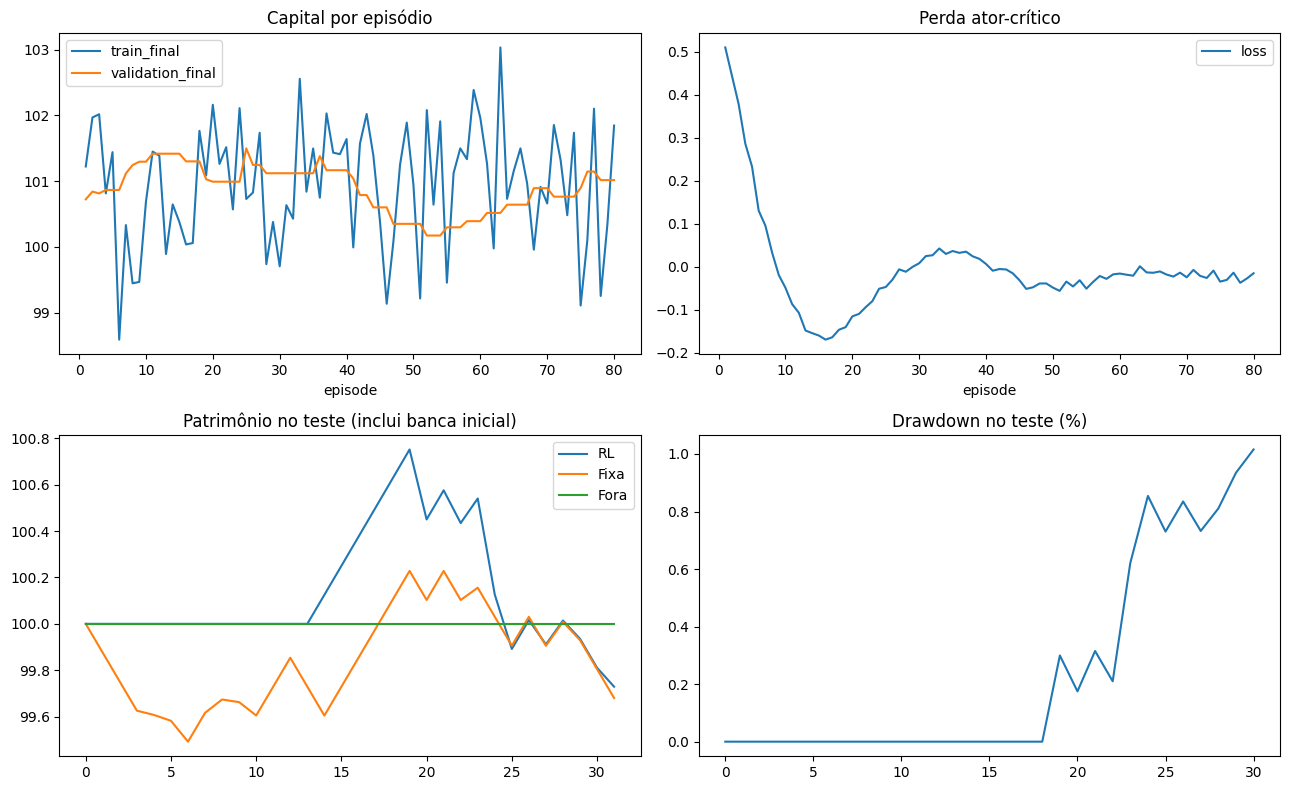

,ocorrências
reason,
FORA,13
CLOSE,10
TP,8


,t,execution_time,action,direction,exposure,tp_distance,sl_distance,capital_before,drawdown,reward,entry,exit,tp,sl,reason,quantity,gross_pnl,costs,net_pnl,capital_after
0,2025-03-18,2025-03-19,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0945,1.0945,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
1,2025-03-19,2025-03-20,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0903,1.0903,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
2,2025-03-20,2025-03-21,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0852,1.0852,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
3,2025-03-21,2025-03-24,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0808,1.0808,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
4,2025-03-24,2025-03-25,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0802,1.0802,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
5,2025-03-25,2025-03-26,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0791,1.0791,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
6,2025-03-26,2025-03-27,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0753,1.0753,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
7,2025-03-27,2025-03-28,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0802,1.0802,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
8,2025-03-28,2025-03-31,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0822,1.0822,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0
9,2025-03-31,2025-04-01,0,0,0.0,0.0,0.0,100.0,0.0,0.0,1.0818,1.0818,NaN,NaN,FORA,0.0,0.0,0.0,0.0,100.0


Artefatos salvos em: C:\projects\Libellula\notebooks\modelo_RL_gestao_banca\resultados


In [11]:
def metrics(env):
    log = pd.DataFrame(env.history)
    trades = log[log.direction != 0]
    return dict(initial=INITIAL_CAPITAL, final=env.equity,
                total_return=env.equity / INITIAL_CAPITAL - 1,
                max_drawdown=log.drawdown.max(), trades=len(trades),
                win_rate=float((trades.net_pnl > 0).mean()) if len(trades) else np.nan)
fixed_test = rollout(model, test_idx, fixed_action=1)
flat_test = rollout(model, test_idx, fixed_action=0)
display(pd.DataFrame({'treino (política final)': metrics(train_evaluation),
                      'validação': metrics(validation_evaluation),
                      'teste RL': metrics(test_evaluation),
                      'teste exposição fixa': metrics(fixed_test),
                      'teste fora': metrics(flat_test)}).T)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
progress.plot(x='episode', y=['train_final', 'validation_final'], ax=axes[0, 0], title='Capital por episódio')
progress.plot(x='episode', y='loss', ax=axes[0, 1], title='Perda ator-crítico')
for label, env in [('RL', test_evaluation), ('Fixa', fixed_test), ('Fora', flat_test)]:
    values = [INITIAL_CAPITAL] + [r['capital_after'] for r in env.history]
    axes[1, 0].plot(values, label=label)
axes[1, 0].set_title('Patrimônio no teste (inclui banca inicial)'); axes[1, 0].legend()
test_log = pd.DataFrame(test_evaluation.history)
axes[1, 1].plot(test_log.drawdown.to_numpy() * 100)
axes[1, 1].set_title('Drawdown no teste (%)')
fig.tight_layout(); plt.show()
display(test_log.reason.value_counts().rename('ocorrências').to_frame())
display(test_log.head(10))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), OUTPUT_DIR / 'actor_critic.pth')
np.savez(OUTPUT_DIR / 'normalizer.npz', mean=mean, scale=scale)
progress.to_csv(OUTPUT_DIR / 'training_progress.csv', index=False)
for name, env in [('train', train_evaluation), ('validation', validation_evaluation),
                  ('test', test_evaluation), ('last_training_episode', last_train)]:
    pd.DataFrame(env.history).to_csv(OUTPUT_DIR / f'{name}_trades.csv', index=False)
fig.savefig(OUTPUT_DIR / 'monitoramento.png', dpi=150)
manifest = dict(seed=SEED, initial_capital=INITIAL_CAPITAL, episodes=EPISODES,
                best_episode=best_episode, features=FEATURES, actions=ACTION_TABLE,
                excluded_transitions={str(t): str(row.execution_time) for t, row in excluded.iterrows()},
                max_exposure=MAX_EXPOSURE, max_risk=MAX_RISK, costs=0.0,
                learning_rate=LEARNING_RATE, gamma=GAMMA, entropy_weight=ENTROPY_WEIGHT,
                drawdown_penalty=DRAWDOWN_PENALTY,
                inputs={str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in [STATE_PATH, RAW_PATH]},
                splits={name: {'rows': len(idx), 'start': str(idx[0]), 'end': str(idx[-1])}
                        for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]},
                train_last=metrics(last_train), test=metrics(test_evaluation))
(OUTPUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Artefatos salvos em:', OUTPUT_DIR)
